# Data Preprocessing

Load the images, encode the labels, and split the dataset into training and validation and test setss

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import tensorflow as tf



from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

 Before loading images into memory, we'll create a list containing each image's location and its category, We need to connect every image to its correct category before training a classification model.

In [28]:
dataset_path = Path("../data/Waste_Dataset")

image_paths = []
labels = []

for folder in sorted(dataset_path.iterdir()):
    if folder.is_dir():
        for image_file in folder.iterdir():
            if image_file.suffix.lower() in [".jpg", ".jpeg", ".png"]:
                image_paths.append(str(image_file))
                labels.append(folder.name)

print("Total images:", len(image_paths))
print("Total labels:", len(labels))
print("Categories:", len(set(labels)))

Total images: 4752
Total labels: 4752
Categories: 9


This converts category names into numbers

In [29]:
label_encoder = LabelEncoder()

encoded_labels = label_encoder.fit_transform(labels)

print("Category mapping:")

for category, number in zip(label_encoder.classes_, range(len(label_encoder.classes_))):
    print(f"{category}: {number}")

Category mapping:
1-Cardboard: 0
2-Food Organics: 1
3-Glass: 2
4-Metal: 3
5-Miscellaneous Trash: 4
6-Paper: 5
7-Plastic: 6
8-Textile Trash: 7
9-Vegetation: 8


Step 6: Split the dataset
We'll divide the 4,752 images into:
- 70% Training: Used to teach the model.
- 15% Validation: Used to evaluate the model during development.
- 15% Test: Used to test the model.

In [30]:
from sklearn.model_selection import train_test_split
# Split the dataset into 70% training and 30% remaining data
X_train, X_temp, y_train, y_temp = train_test_split(
    image_paths,
    encoded_labels,
    test_size=0.30,
    random_state=42,
    stratify=encoded_labels
)

# Split the remaining data equally into 15% validation and 15% testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Display the number of images in each subset
print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Testing images:", len(X_test))

print("\nTotal images:", len(X_train) + len(X_val) + len(X_test))


Training images: 3326
Validation images: 713
Testing images: 713

Total images: 4752


Our images are 524 × 524. We'll resize them to 224 × 224, which is a common input size for CNN and MobileNet models.


In [31]:

IMG_SIZE = 224

def load_images(paths):
    images = []

    for path in paths:
        image = cv2.imread(path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = cv2.resize(image, (IMG_SIZE, IMG_SIZE))
        images.append(image)

    return np.array(images)


# Load training images
X_train_images = load_images(X_train)

# Load validation images
X_val_images = load_images(X_val)

# Load testing images
X_test_images = load_images(X_test)


# Display dataset shapes
print("Training shape:", X_train_images.shape)
print("Validation shape:", X_val_images.shape)
print("Testing shape:", X_test_images.shape)


Training shape: (3326, 224, 224, 3)
Validation shape: (713, 224, 224, 3)
Testing shape: (713, 224, 224, 3)


We need to confirm that the images have three colour channels and that their pixel values are in the expected range.

In [32]:
print("Image shape:", X_train_images[0].shape)
print("Data type:", X_train_images.dtype)
print("Pixel range:", X_train_images.min(), "-", X_train_images.max())

Image shape: (224, 224, 3)
Data type: uint8
Pixel range: 0 - 255


Normalize the images, Smaller consistent input values generally help neural networks train more effectively.

In [33]:
X_train_normalized = X_train_images.astype("float32") / 255.0
X_val_normalized = X_val_images.astype("float32") / 255.0
X_test_normalized = X_test_images.astype("float32") / 255.0

print("Training pixel range:", X_train_normalized.min(), "-", X_train_normalized.max())
print("Validation pixel range:", X_val_normalized.min(), "-", X_val_normalized.max())
print("Testing pixel range:", X_test_normalized.min(), "-", X_test_normalized.max())

print("Data type:", X_train_normalized.dtype)

Training pixel range: 0.0 - 1.0
Validation pixel range: 0.0 - 1.0
Testing pixel range: 0.0 - 1.0
Data type: float32


 verify that the image still looks correct after resizing and normalization.

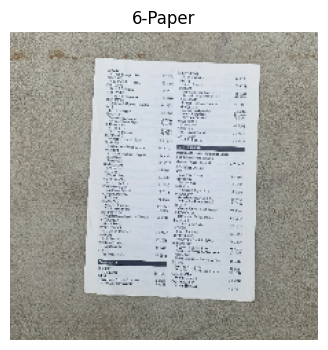

In [34]:
plt.figure(figsize=(4, 4))
plt.imshow(X_train_normalized[0])
plt.title(label_encoder.inverse_transform([y_train[0]])[0])
plt.axis("off")
plt.show()

This function processes one image at a time when the training pipeline requests it, rather than loading the entire dataset into RAM.
Reads images from your dataset.
Converts them into RGB format.
Resizes them to 224 × 224.
Normalizes pixels to 0–1.
Prepares each image and its label for TensorFlow.

In [35]:
IMG_SIZE = 224
BATCH_SIZE = 32

def load_and_preprocess_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.io.decode_image(image, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])

    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32) / 255.0

    return image, label

### Create TensorFlow Datasets

Prepare training and validation and test data in batches of 32 images. This allows TensorFlow to load and preprocess images efficiently without loading the entire dataset into memory.

In [36]:

# Create the training dataset from image paths and labels
train_dataset = tf.data.Dataset.from_tensor_slices(
    (X_train, y_train)
)

# Apply image preprocessing
train_dataset = train_dataset.map(
    load_and_preprocess_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

# Shuffle training images to improve learning
train_dataset = train_dataset.shuffle(
    buffer_size=len(X_train),
    seed=42
)

# Group images into batches of 32 and prepare the next batch
train_dataset = train_dataset.batch(BATCH_SIZE)
train_dataset = train_dataset.prefetch(tf.data.AUTOTUNE)


# Create the validation dataset
val_dataset = tf.data.Dataset.from_tensor_slices(
    (X_val, y_val)
)

# Apply the same preprocessing without shuffling
val_dataset = val_dataset.map(
    load_and_preprocess_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

# Group validation images into batches and prepare them efficiently
val_dataset = val_dataset.batch(BATCH_SIZE)
val_dataset = val_dataset.prefetch(tf.data.AUTOTUNE)


# Create the testing dataset
test_dataset = tf.data.Dataset.from_tensor_slices(
    (X_test, y_test)
)

# Apply the same preprocessing without shuffling
test_dataset = test_dataset.map(
    load_and_preprocess_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

# Group testing images into batches and prepare them efficiently
test_dataset = test_dataset.batch(BATCH_SIZE)
test_dataset = test_dataset.prefetch(tf.data.AUTOTUNE)


Each batch should contain 32 images.,
Each image should have dimensions 224 × 224 × 3.,
Each image should have a corresponding label.,

Pixel values should be between 0 and 1.

In [23]:

# Get one batch from each dataset
train_images, train_labels = next(iter(train_dataset))
val_images, val_labels = next(iter(val_dataset))
test_images, test_labels = next(iter(test_dataset))

# Check the batch shapes and pixel values
print("Training batch shape:", train_images.shape)
print("Training labels shape:", train_labels.shape)

print("Validation batch shape:", val_images.shape)
print("Validation labels shape:", val_labels.shape)

print("Testing batch shape:", test_images.shape)
print("Testing labels shape:", test_labels.shape)

print("Pixel range:", tf.reduce_min(train_images).numpy(),
      "-", tf.reduce_max(train_images).numpy())


Training batch shape: (32, 224, 224, 3)
Training labels shape: (32,)
Validation batch shape: (32, 224, 224, 3)
Validation labels shape: (32,)
Testing batch shape: (32, 224, 224, 3)
Testing labels shape: (32,)
Pixel range: 0.0 - 1.0


### Custom CNN Model

Build a Convolutional Neural Network (CNN) to classify waste images into nine categories.

In [37]:
# Import the layers needed to build our CNN
from tensorflow.keras import layers, models

In [38]:
# Define the input shape for our images
input_shape = (224, 224, 3)

# Create the first convolutional layer
model = models.Sequential([
    layers.Input(shape=input_shape),
    layers.Conv2D(32, (3, 3), activation="relu")
])

# Reduce feature map dimensions while keeping important features using maxpooling
model.add(layers.MaxPooling2D(pool_size=(2, 2)))

Our first convolutional layer detects basic features such as edges and simple textures.

Now we'll add another layers to learn more complex patterns

In [39]:
# Detect more complex image features,layer 2
model.add(layers.Conv2D(64, (3, 3), activation="relu"))

# Reduce the feature map size again
model.add(layers.MaxPooling2D(pool_size=(2, 2)))


# Detect more complex image features,layer 3
model.add(layers.Conv2D(128, (3, 3), activation="relu"))

# Reduce the feature map size again
model.add(layers.MaxPooling2D(pool_size=(2, 2)))


# Convert feature maps into a one-dimensional vector
#Global Average Pooling summarizes the features detected in an image into a smaller list of numbers, same as flattening,
# but it takes the average of each feature map instead of just stacking them
model.add(layers.GlobalAveragePooling2D())


# Learn how to combine the extracted features
#The Dense layer learns how to combine those features to recognize patterns associated with waste categories

model.add(layers.Dense(128, activation="relu"))




# Reduce overfitting by randomly disabling 30% of neurons during each training step.
model.add(layers.Dropout(0.3))


# Final layer that makes the actual classification.
# Classify the image into one of the nine waste categories ,because we have 9 possible outcomes, one for each waste category. 
# The softmax activation function is used to convert the output into a probability distribution over the nine classes
# sum of all probabilities of them should be equal to 1
model.add(layers.Dense(9, activation="softmax"))



# Display the CNN architecture and number of parameters
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 9)              │         1,161 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,921 (433.29 KB)

 Trainable params: 110,921 (433.29 KB)

 Non-trainable params: 0 (0.00 B)

Compile the CNN
Configure the optimizer, loss function, and evaluation metric before training.

In [40]:
# Configure the model for training
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

### Training Callbacks

Prepare callbacks to monitor model performance, stop unnecessary training, and save the best model.

In [43]:
# Stop training if validation loss does not improve
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Save the best model during training
model_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath="../models/custom_cnn_best.keras",
    monitor="val_loss",
    save_best_only=True
)

Train the Custom CNN
,Train the model using the training dataset and monitor its performance on the validation dataset.

In [45]:
# Train the CNN model

history = model.fit(
    X_train_normalized,
    y_train,
    validation_data=(X_val_normalized, y_val),
    epochs=20,
    callbacks=[
        early_stopping,
         model_checkpoint
    ]
)


Epoch 1/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 54s 506ms/step - accuracy: 0.2138 - loss: 2.1128 - val_accuracy: 0.2525 - val_loss: 2.0081
Epoch 2/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 100s 669ms/step - accuracy: 0.2679 - loss: 1.9818 - val_accuracy: 0.3100 - val_loss: 1.8653
Epoch 3/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 38s 368ms/step - accuracy: 0.3334 - loss: 1.8051 - val_accuracy: 0.3955 - val_loss: 1.7967
Epoch 4/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 40s 380ms/step - accuracy: 0.3746 - loss: 1.7342 - val_accuracy: 0.4502 - val_loss: 1.6151
Epoch 5/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 54s 522ms/step - accuracy: 0.4269 - loss: 1.6035 - val_accuracy: 0.4797 - val_loss: 1.5231
Epoch 6/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 47s 457ms/step - accuracy: 0.4519 - loss: 1.5427 - val_accuracy: 0.5288 - val_loss: 1.4468
Epoch 7/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 50s 478ms/step - accuracy: 0.4582 - loss: 1.5228 - val_accuracy: 0.4951 - val_loss: 1.4898
Epoch 8/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 49s 471ms/step - accuracy: 0.4732 - loss: 

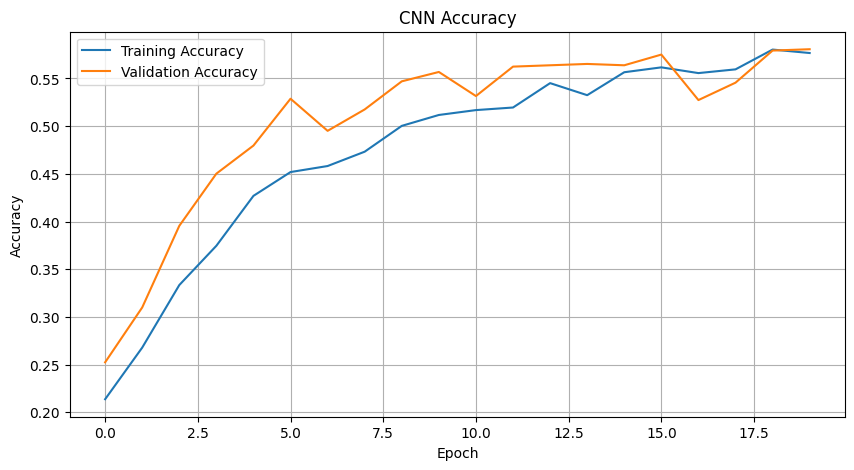

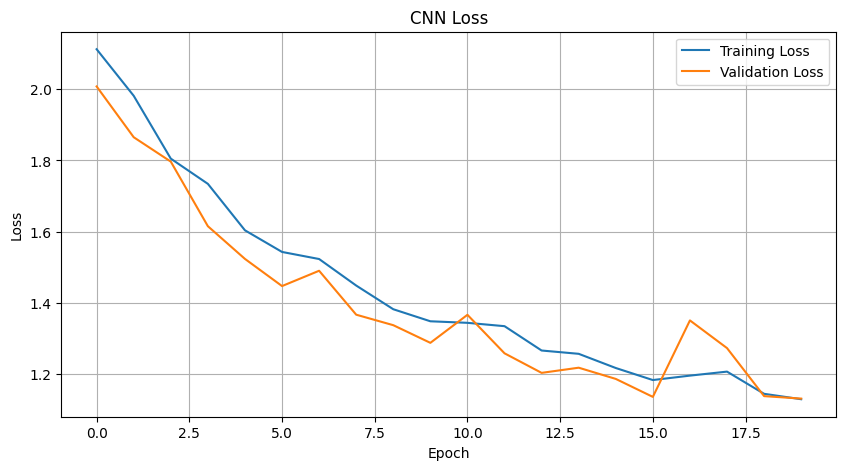

In [46]:
# Plot training and validation accuracy
plt.figure(figsize=(10, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()


# Plot training and validation loss
plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [48]:
print("Epochs completed:", len(history.history["loss"]))

print("Final training accuracy:", history.history["accuracy"][-1])
print("Final validation accuracy:", history.history["val_accuracy"][-1])

print("Final training loss:", history.history["loss"][-1])
print("Final validation loss:", history.history["val_loss"][-1])

print("Best validation accuracy:", max(history.history["val_accuracy"]))
print("Best validation loss:", min(history.history["val_loss"]))

print("Best validation loss epoch:",
      np.argmin(history.history["val_loss"]) + 1)

print("Best validation accuracy epoch:",
      np.argmax(history.history["val_accuracy"]) + 1)

Epochs completed: 20
Final training accuracy: 0.5766686797142029
Final validation accuracy: 0.5806451439857483
Final training loss: 1.1285792589187622
Final validation loss: 1.1303448677062988
Best validation accuracy: 0.5806451439857483
Best validation loss: 1.1303448677062988
Best validation loss epoch: 20
Best validation accuracy epoch: 20


In [51]:
# Load the model with the best validation loss
best_cnn_model = tf.keras.models.load_model(
    "../models/custom_cnn_best.keras"
)

# Evaluate the saved model using the same validation data
# and preprocessing used during training
cnn_val_loss, cnn_val_accuracy = best_cnn_model.evaluate(
    X_val_normalized,
    y_val
)

print("Best CNN validation loss:", cnn_val_loss)
print("Best CNN validation accuracy:", cnn_val_accuracy)

23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 86ms/step - accuracy: 0.5806 - loss: 1.1303
Best CNN validation loss: 1.1303448677062988
Best CNN validation accuracy: 0.5806451439857483


Classification report.It include Precision, Recall, F1-score.

In [52]:
from sklearn.metrics import classification_report

# Get the true labels from the validation dataset
y_true = np.concatenate([
    labels.numpy() for images, labels in val_dataset
])

# Generate model predictions
y_prob = best_cnn_model.predict(val_dataset)

# Convert probabilities into predicted class numbers
y_pred = np.argmax(y_prob, axis=1)

# Display precision, recall, and F1-score for each category
print(classification_report(
    y_true,
    y_pred,
    target_names=label_encoder.classes_,
    zero_division=0
))

23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 100ms/step
                       precision    recall  f1-score   support

          1-Cardboard       0.74      0.38      0.50        69
      2-Food Organics       0.70      0.72      0.71        61
              3-Glass       0.70      0.59      0.64        63
              4-Metal       0.60      0.59      0.60       119
5-Miscellaneous Trash       0.30      0.41      0.34        74
              6-Paper       0.58      0.44      0.50        75
            7-Plastic       0.52      0.75      0.61       138
      8-Textile Trash       0.46      0.12      0.20        48
         9-Vegetation       0.78      0.89      0.83        66

             accuracy                           0.57       713
            macro avg       0.60      0.54      0.55       713
         weighted avg       0.59      0.57      0.56       713



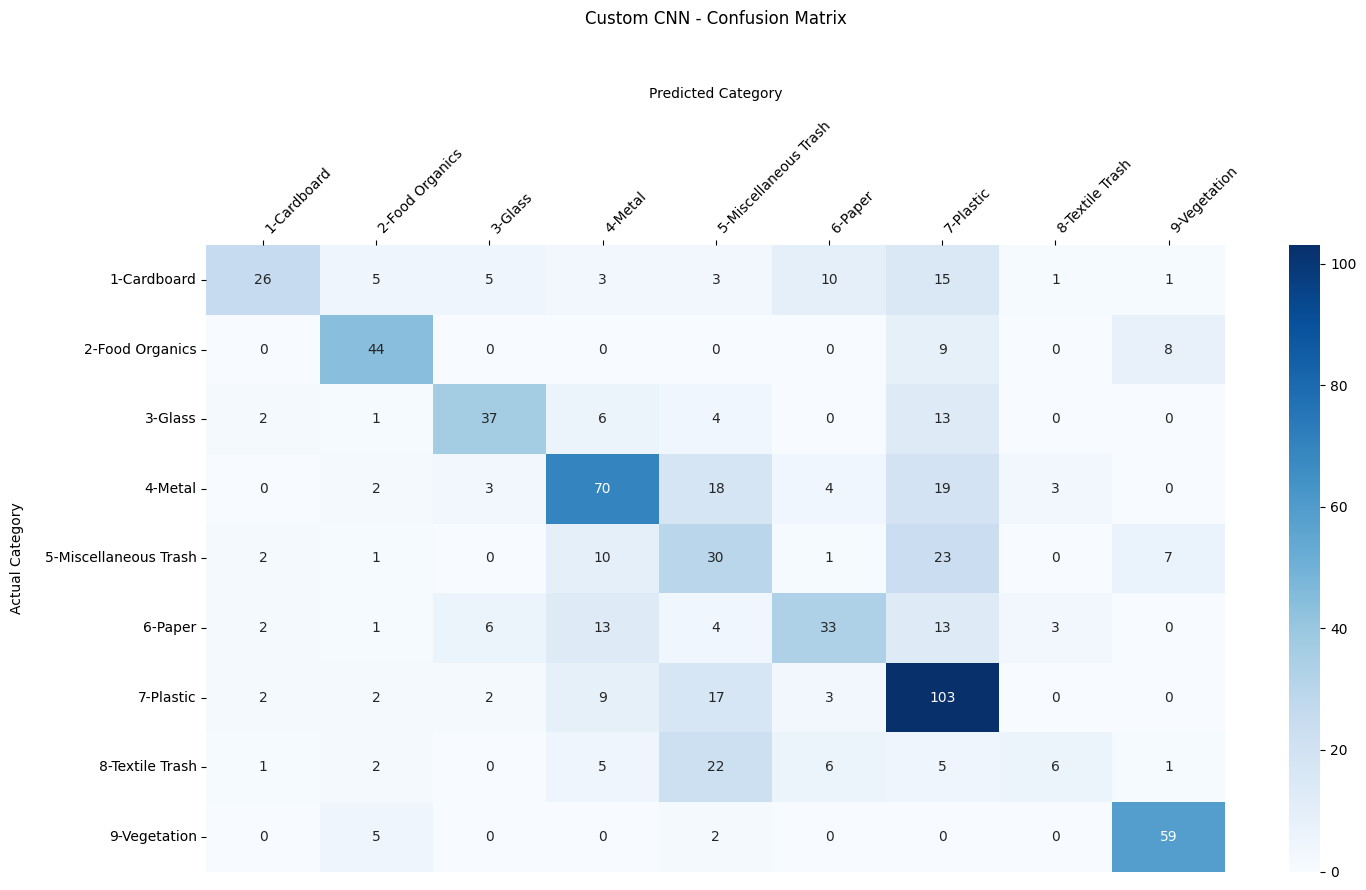

In [53]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Create the confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Plot the confusion matrix
plt.figure(figsize=(15, 9))

ax = sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

# Move predicted category labels to the top
ax.xaxis.tick_top()
ax.xaxis.set_label_position("top")

# Add titles and labels
plt.title("Custom CNN - Confusion Matrix", pad=45)
plt.xlabel("Predicted Category", labelpad=15)
plt.ylabel("Actual Category", labelpad=15)

# Adjust label rotation and layout
plt.xticks(rotation=45, ha="left")
plt.yticks(rotation=0)

plt.tight_layout()
plt.savefig(
    "../results/figures/custom_cnn_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Model 2: MobileNetV2 Transfer Learning

In this experiment, we use MobileNetV2 pretrained on ImageNet.
We will adapt it to classify our nine waste categories.

Reads an image from its file path.



Decodes it into RGB format.



Resizes it to 224 × 224.



Scales pixel values to the range MobileNetV2 expects.



Returns the processed image and its label.

In [54]:
import tensorflow as tf

def load_and_preprocess_mobilenet(image_path, label):
    # Read the image from its file path
    image = tf.io.read_file(image_path)

    # Decode the image into RGB format
    image = tf.io.decode_image(image, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])

    # Resize the image to 224x224
    image = tf.image.resize(image, [224, 224])

    # Normalize pixel values to the range [-1, 1] for MobileNetV2
    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)

    return image, label

In [56]:
# Create the MobileNetV2 training dataset
mobilenet_train_dataset = tf.data.Dataset.from_tensor_slices((X_train, y_train))

# Apply MobileNetV2 preprocessing to each image
mobilenet_train_dataset = mobilenet_train_dataset.map(
    load_and_preprocess_mobilenet,
    num_parallel_calls=tf.data.AUTOTUNE
)

# Shuffle the training data to improve learning
mobilenet_train_dataset = mobilenet_train_dataset.shuffle(
    buffer_size=len(X_train),
    seed=42
)

# Group images into batches and improve loading performance
mobilenet_train_dataset = mobilenet_train_dataset.batch(BATCH_SIZE)
mobilenet_train_dataset = mobilenet_train_dataset.prefetch(tf.data.AUTOTUNE)


# Create the MobileNetV2 validation dataset
mobilenet_val_dataset = tf.data.Dataset.from_tensor_slices((X_val, y_val))

# Apply the same preprocessing without shuffling
mobilenet_val_dataset = mobilenet_val_dataset.map(
    load_and_preprocess_mobilenet,
    num_parallel_calls=tf.data.AUTOTUNE
)

# Group validation images into batches
mobilenet_val_dataset = mobilenet_val_dataset.batch(BATCH_SIZE)
mobilenet_val_dataset = mobilenet_val_dataset.prefetch(tf.data.AUTOTUNE)


# Create the MobileNetV2 testing dataset
mobilenet_test_dataset = tf.data.Dataset.from_tensor_slices((X_test, y_test))

# Apply the same preprocessing without shuffling
mobilenet_test_dataset = mobilenet_test_dataset.map(
    load_and_preprocess_mobilenet,
    num_parallel_calls=tf.data.AUTOTUNE
)

# Group testing images into batches
mobilenet_test_dataset = mobilenet_test_dataset.batch(BATCH_SIZE)
mobilenet_test_dataset = mobilenet_test_dataset.prefetch(tf.data.AUTOTUNE)


# Check one batch from the training dataset
for images, labels in mobilenet_train_dataset.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Minimum pixel value: -1.0
Maximum pixel value: 1.0


### Load pretrained MobileNetV2
MobileNetV2 is already trained on ImageNet, a dataset containing millions of images. We'll reuse its learned visual features instead of learning everything from zero.

In [57]:
# Load MobileNetV2 pretrained on ImageNet
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze the pretrained layers
base_model.trainable = False

# Display the model architecture
base_model.summary()

Model: "mobilenetv2_1.00_224"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_2[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,257,984 (8.61 MB)

In [59]:
# Create data augmentation layers
# Introduce small variations in training images to help the model generalize better
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
])

In [61]:

# Build the complete MobileNetV2 model
# Define the input layer
inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

# Apply data augmentation
x = data_augmentation(inputs)

# Extract image features using pretrained MobileNetV2
x = base_model(x, training=False)

# Reduce the feature maps into a single feature vector
x = layers.GlobalAveragePooling2D()(x)

# Reduce overfitting
x = layers.Dropout(0.3)(x)

# Classify images into our nine waste categories
outputs = layers.Dense(9, activation="softmax")(x)

# Create the complete MobileNetV2 model
mobilenet_model = tf.keras.Model(inputs, outputs)

# Display the model architecture
mobilenet_model.summary()

Model: "functional_44"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_2 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 9)              │        11,529 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,269,513 (8.66 MB)

 Trainable params: 11,529 (45.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [62]:
# Compile the MobileNetV2 model
mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Stop training if validation loss stops improving
mobilenet_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Save the model with the best validation loss
mobilenet_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath="../models/mobilenetv2_best.keras",
    monitor="val_loss",
    save_best_only=True
)


# Train the MobileNetV2 model
mobilenet_history = mobilenet_model.fit(
    mobilenet_train_dataset,
    validation_data=mobilenet_val_dataset,
    epochs=20,
    callbacks=[
        mobilenet_early_stopping,
        mobilenet_checkpoint
    ]
)

Epoch 1/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 97s 850ms/step - accuracy: 0.1870 - loss: 2.3509 - val_accuracy: 0.2595 - val_loss: 1.9362
Epoch 2/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 177s 1s/step - accuracy: 0.3130 - loss: 1.8991 - val_accuracy: 0.4194 - val_loss: 1.6148
Epoch 3/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 135s 1s/step - accuracy: 0.4170 - loss: 1.6174 - val_accuracy: 0.5105 - val_loss: 1.4129
Epoch 4/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 142s 1s/step - accuracy: 0.4874 - loss: 1.4334 - val_accuracy: 0.5764 - val_loss: 1.2719
Epoch 5/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 65s 405ms/step - accuracy: 0.5325 - loss: 1.3451 - val_accuracy: 0.6045 - val_loss: 1.1764
Epoch 6/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 57s 519ms/step - accuracy: 0.5725 - loss: 1.2314 - val_accuracy: 0.6297 - val_loss: 1.1040
Epoch 7/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 80s 747ms/step - accuracy: 0.6010 - loss: 1.1461 - val_accuracy: 0.6452 - val_loss: 1.0489
Epoch 8/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 77s 710ms/step - accuracy: 0.6170 - loss: 1.0836 

In [64]:
# Load the best saved MobileNetV2 model
best_mobilenet_model = tf.keras.models.load_model(
    "../models/mobilenetv2_best.keras"
)

# Evaluate the model on the validation dataset
mobilenet_val_loss, mobilenet_val_accuracy = best_mobilenet_model.evaluate(
    mobilenet_val_dataset
)

# Display the evaluation results
print("MobileNetV2 Validation Loss:", mobilenet_val_loss)
print("MobileNetV2 Validation Accuracy:", mobilenet_val_accuracy)

23/23 ━━━━━━━━━━━━━━━━━━━━ 9s 331ms/step - accuracy: 0.7111 - loss: 0.7891
MobileNetV2 Validation Loss: 0.7890504002571106
MobileNetV2 Validation Accuracy: 0.7110799551010132


In [65]:
# Get the actual labels from the MobileNetV2 validation dataset
mobilenet_y_true = np.concatenate([
    labels.numpy()
    for images, labels in mobilenet_val_dataset
])

# Generate predictions using the best MobileNetV2 model
mobilenet_y_prob = best_mobilenet_model.predict(mobilenet_val_dataset)

# Convert probabilities into predicted class labels
mobilenet_y_pred = np.argmax(mobilenet_y_prob, axis=1)

# Generate the classification report
# Precision, recall, and F1-score for each category
print(classification_report(
    mobilenet_y_true,
    mobilenet_y_pred,
    target_names=label_encoder.classes_,
    zero_division=0
))

23/23 ━━━━━━━━━━━━━━━━━━━━ 10s 388ms/step
                       precision    recall  f1-score   support

          1-Cardboard       0.75      0.55      0.63        69
      2-Food Organics       0.84      0.62      0.72        61
              3-Glass       0.76      0.60      0.67        63
              4-Metal       0.73      0.78      0.75       119
5-Miscellaneous Trash       0.60      0.50      0.54        74
              6-Paper       0.67      0.81      0.73        75
            7-Plastic       0.69      0.78      0.73       138
      8-Textile Trash       0.61      0.69      0.65        48
         9-Vegetation       0.79      0.94      0.86        66

             accuracy                           0.71       713
            macro avg       0.72      0.70      0.70       713
         weighted avg       0.71      0.71      0.71       713



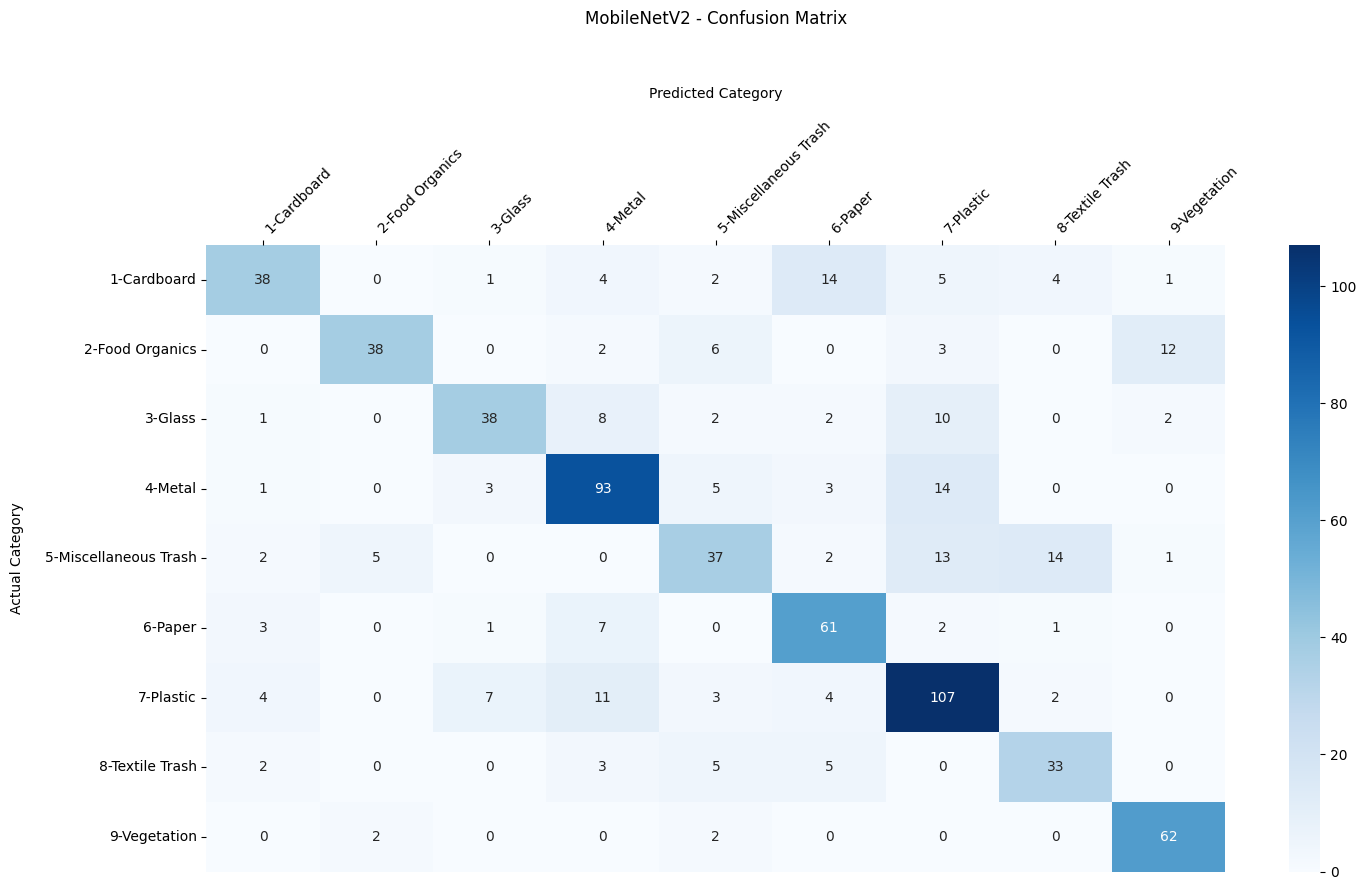

In [66]:
# Calculate the MobileNetV2 confusion matrix
mobilenet_cm = confusion_matrix(
    mobilenet_y_true,
    mobilenet_y_pred
)

# Plot the confusion matrix
plt.figure(figsize=(15, 9))

ax = sns.heatmap(
    mobilenet_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

# Place predicted categories at the top
ax.xaxis.tick_top()
ax.xaxis.set_label_position("top")

plt.title("MobileNetV2 - Confusion Matrix", pad=45)
plt.xlabel("Predicted Category", labelpad=15)
plt.ylabel("Actual Category", labelpad=15)
plt.xticks(rotation=45, ha="left")
plt.yticks(rotation=0)
plt.tight_layout()

# Save the confusion matrix
plt.savefig(
    "../results/figures/mobilenetv2_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [68]:
# Display the confusion matrix as a readable table
mobilenet_cm_df = pd.DataFrame(
    mobilenet_cm,
    index=label_encoder.classes_,
    columns=label_encoder.classes_
)

display(mobilenet_cm_df)

,1-Cardboard,2-Food Organics,3-Glass,4-Metal,5-Miscellaneous Trash,6-Paper,7-Plastic,8-Textile Trash,9-Vegetation
1-Cardboard,38,0,1,4,2,14,5,4,1
2-Food Organics,0,38,0,2,6,0,3,0,12
3-Glass,1,0,38,8,2,2,10,0,2
4-Metal,1,0,3,93,5,3,14,0,0
5-Miscellaneous Trash,2,5,0,0,37,2,13,14,1
6-Paper,3,0,1,7,0,61,2,1,0
7-Plastic,4,0,7,11,3,4,107,2,0
8-Textile Trash,2,0,0,3,5,5,0,33,0
9-Vegetation,0,2,0,0,2,0,0,0,62


#### we want to use the trained model on a new image.

In [91]:
# Load the best saved MobileNetV2 model
best_mobilenet_model = tf.keras.models.load_model(
    "../models/mobilenetv2_best.keras"
)


# Define a function to predict the waste category of one image
def predict_waste_image(image_path):

    # Read the image
    image = tf.io.read_file(str(image_path))

    # Decode the image into RGB format
    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    # Resize the image to 224x224
    image = tf.image.resize(image, [224, 224])

    # Apply MobileNetV2 preprocessing
    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)

    # Add a batch dimension because the model expects batches of images
    image = tf.expand_dims(image, axis=0)

    # Predict probabilities for the nine categories
    probabilities = best_mobilenet_model.predict(image, verbose=0)[0]

    # Find the category with the highest probability
    predicted_index = np.argmax(probabilities)

    # Get the category name
    predicted_category = label_encoder.classes_[predicted_index]

    # Get the prediction confidence
    confidence = probabilities[predicted_index] * 100

    return predicted_category, confidence, probabilities

#### TEST IT 


In [92]:
# Select one image from the validation dataset
test_image_path = X_val[0]

# Predict its waste category
predicted_category, confidence, probabilities = predict_waste_image(
    test_image_path
)

print("Predicted Category:", predicted_category)
print(f"Confidence: {confidence:.2f}%")

Predicted Category: 4-Metal
Confidence: 84.40%


This cell will display the original image, its predicted category, confidence, and probabilities for all nine classes.

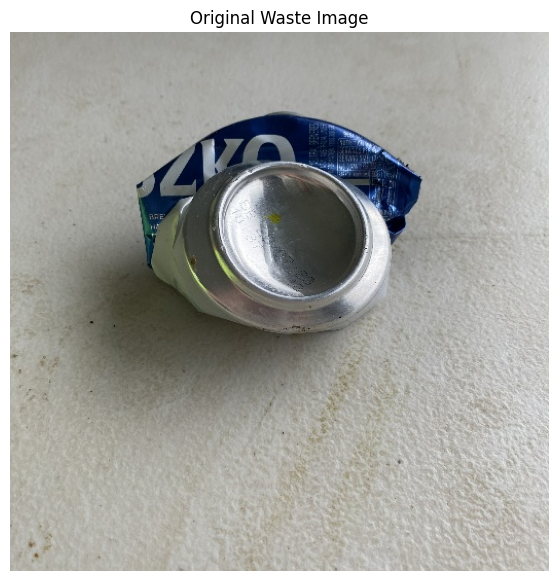

Predicted Category: 4-Metal
Confidence: 84.40%


,Category,Probability (%)
3,4-Metal,84.400002
6,7-Plastic,10.790000
2,3-Glass,3.740000
4,5-Miscellaneous Trash,0.370000
5,6-Paper,0.330000
7,8-Textile Trash,0.200000
0,1-Cardboard,0.160000
8,9-Vegetation,0.000000
1,2-Food Organics,0.000000


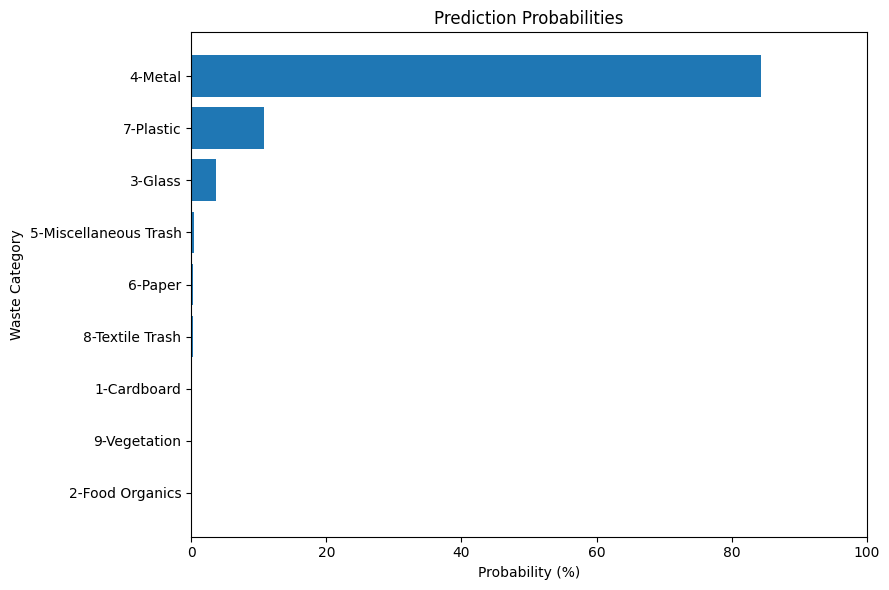

In [93]:
# Read the original image directly from its file path
original_image = cv2.imread(str(test_image_path))

# Check that the image was loaded successfully
if original_image is None:
    raise FileNotFoundError(f"Could not load image: {test_image_path}")

# Convert BGR to RGB
original_image = cv2.cvtColor(original_image, cv2.COLOR_BGR2RGB)


# Create a DataFrame containing all nine category probabilities
probability_df = pd.DataFrame({
    "Category": label_encoder.classes_,
    "Probability (%)": probabilities * 100
})

# Sort probabilities from highest to lowest
probability_df = probability_df.sort_values(
    by="Probability (%)",
    ascending=False
)


# Display the original image
plt.figure(figsize=(7, 7))
plt.imshow(original_image)
plt.title("Original Waste Image")
plt.axis("off")
plt.show()


# Display prediction results
print("Predicted Category:", predicted_category)
print(f"Confidence: {confidence:.2f}%")


# Display all nine category probabilities
display(probability_df.round(2))


# Display prediction probability chart
plt.figure(figsize=(9, 6))

plt.barh(
    probability_df["Category"],
    probability_df["Probability (%)"]
)

plt.xlabel("Probability (%)")
plt.ylabel("Waste Category")
plt.title("Prediction Probabilities")

plt.xlim(0, 100)
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

## Model Comparison

Two models were trained and evaluated using the same validation dataset:

1. Custom CNN
2. MobileNetV2 Transfer Learning

MobileNetV2 achieved better validation accuracy, lower validation loss, and a higher macro F1-score.

Therefore, MobileNetV2 is selected as the best-performing model.

In [95]:
# Compare the performance of both models using the new validation results

comparison_df = pd.DataFrame({
    "Metric": [
        "Validation Accuracy",
        "Validation Loss"
    ],
    "Custom CNN": [
        cnn_val_accuracy,
        cnn_val_loss
    ],
    "MobileNetV2": [
        mobilenet_val_accuracy,
        mobilenet_val_loss
    ]
})

# Display the comparison table
display(comparison_df.round(4))

,Metric,Custom CNN,MobileNetV2
0,Validation Accuracy,0.5806,0.7111
1,Validation Loss,1.1303,0.7891


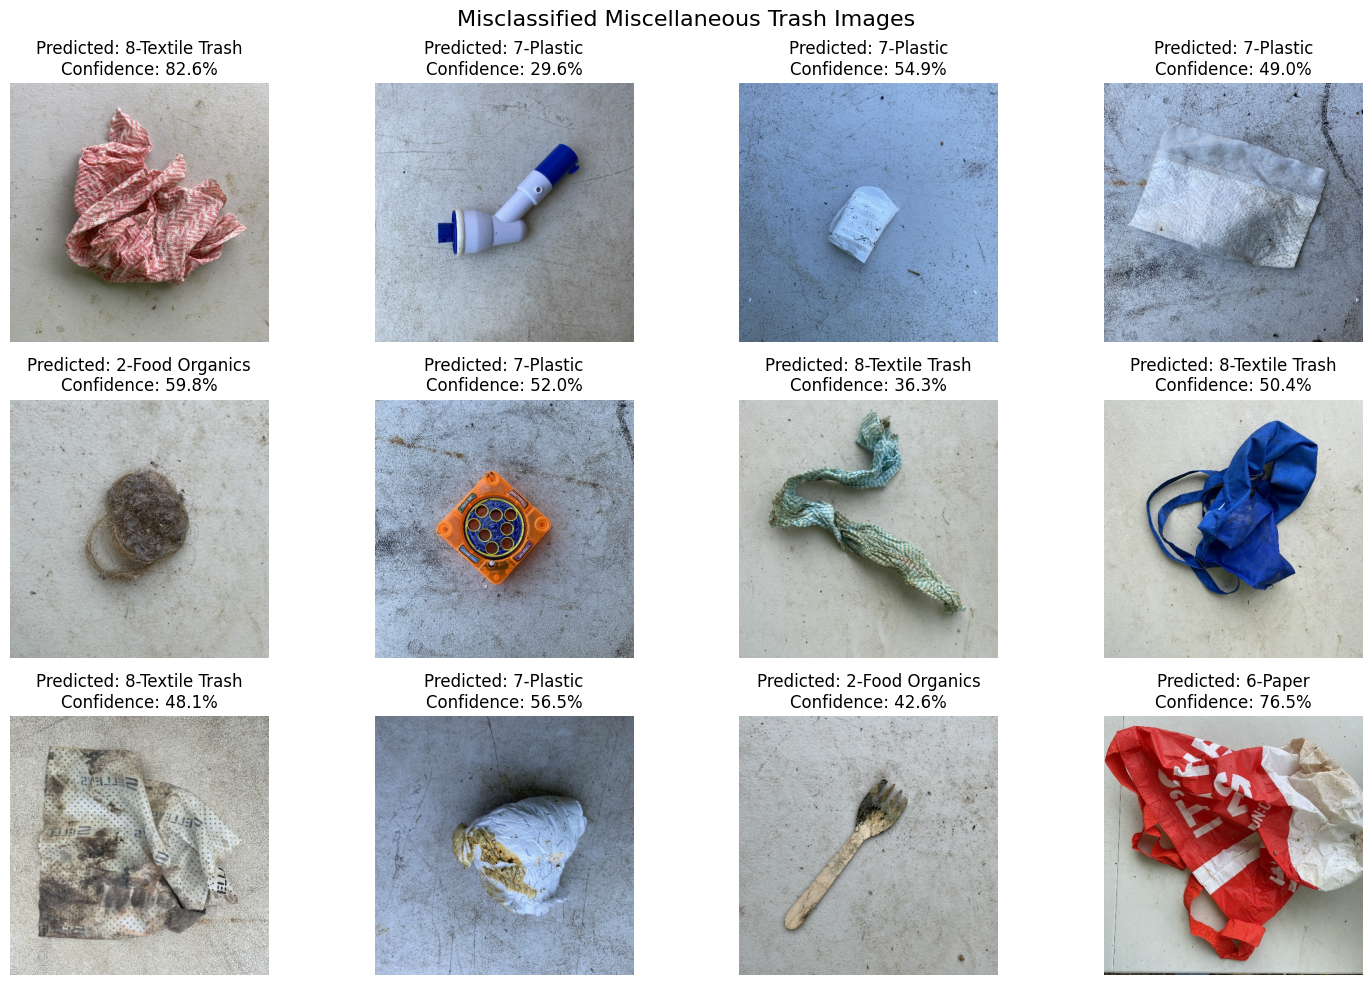

In [97]:
# Find the index of Miscellaneous Trash
misc_index = np.where(
    label_encoder.classes_ == "5-Miscellaneous Trash"
)[0][0]

# Find images that actually belong to Miscellaneous Trash
# but were classified incorrectly
misclassified_indices = np.where(
    (mobilenet_y_true == misc_index) &
    (mobilenet_y_pred != misc_index)
)[0]

# Select up to 12 images to inspect
selected_indices = misclassified_indices[:12]

# Display the misclassified images
plt.figure(figsize=(15, 10))

for position, index in enumerate(selected_indices):

    # Read the original image
    image = cv2.imread(str(X_val[index]))

    # Convert BGR to RGB
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Get the predicted category
    predicted_category = label_encoder.classes_[
        mobilenet_y_pred[index]
    ]

    # Get prediction confidence
    confidence = mobilenet_y_prob[index][
        mobilenet_y_pred[index]
    ] * 100

    # Display image
    plt.subplot(3, 4, position + 1)
    plt.imshow(image)

    plt.title(
        f"Predicted: {predicted_category}\n"
        f"Confidence: {confidence:.1f}%"
    )

    plt.axis("off")

plt.suptitle(
    "Misclassified Miscellaneous Trash Images",
    fontsize=16
)

plt.tight_layout()
plt.show()

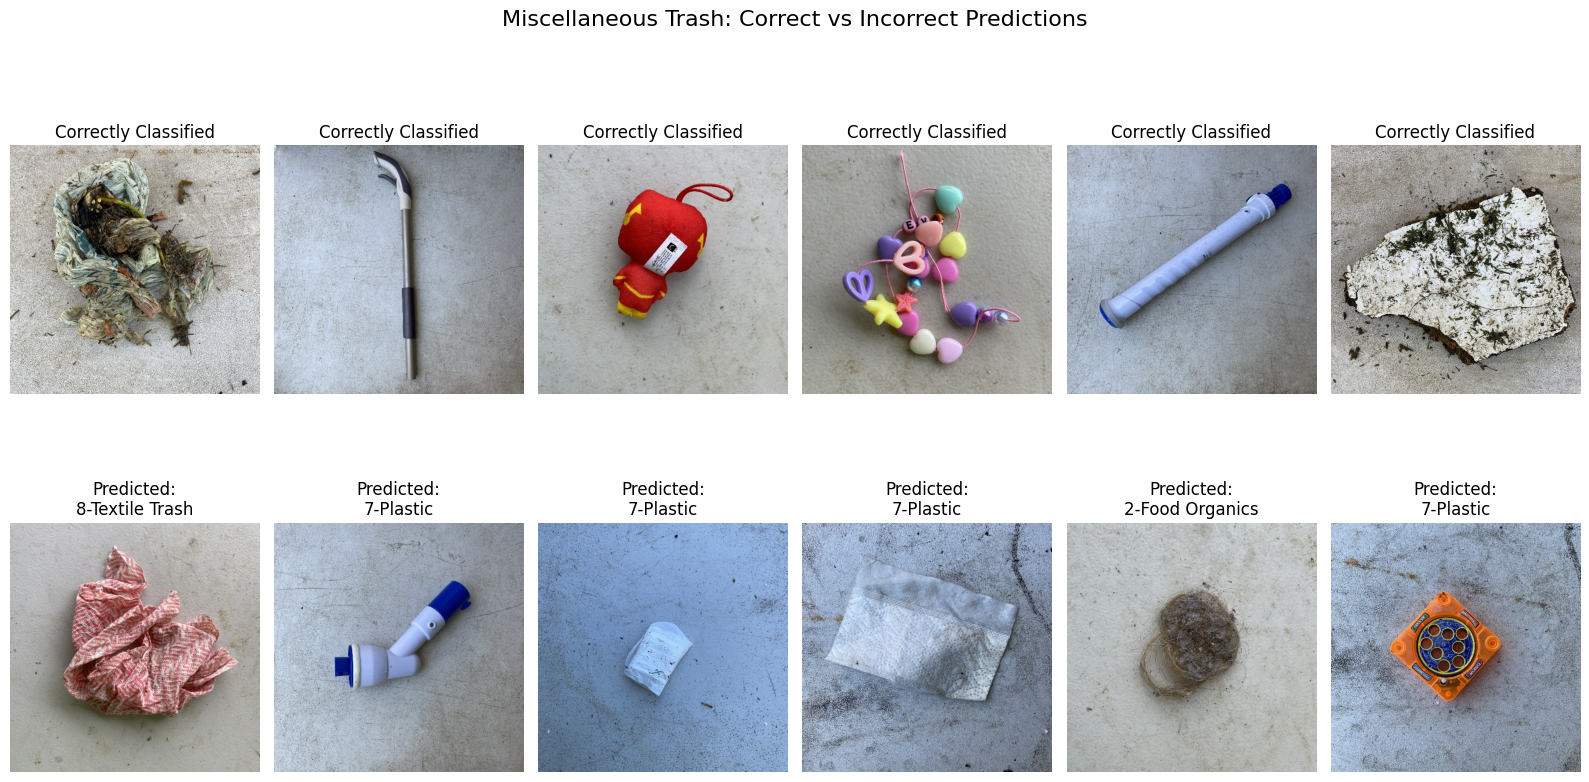

In [98]:
# Find correctly classified Miscellaneous Trash images
correct_indices = np.where(
    (mobilenet_y_true == misc_index) &
    (mobilenet_y_pred == misc_index)
)[0]

# Find incorrectly classified Miscellaneous Trash images
incorrect_indices = np.where(
    (mobilenet_y_true == misc_index) &
    (mobilenet_y_pred != misc_index)
)[0]

# Select 6 images from each group
selected_correct = correct_indices[:6]
selected_incorrect = incorrect_indices[:6]

# Create a comparison visualization
plt.figure(figsize=(16, 9))

# Display correctly classified images
for i, index in enumerate(selected_correct):

    image = cv2.imread(str(X_val[index]))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.subplot(2, 6, i + 1)
    plt.imshow(image)
    plt.title("Correctly Classified")
    plt.axis("off")


# Display incorrectly classified images
for i, index in enumerate(selected_incorrect):

    image = cv2.imread(str(X_val[index]))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    predicted_category = label_encoder.classes_[
        mobilenet_y_pred[index]
    ]

    plt.subplot(2, 6, i + 7)
    plt.imshow(image)
    plt.title(f"Predicted:\n{predicted_category}")
    plt.axis("off")


plt.suptitle(
    "Miscellaneous Trash: Correct vs Incorrect Predictions",
    fontsize=16
)

plt.tight_layout()
plt.show()

,Category,Precision,Recall,F1-Score,Support
0,1-Cardboard,0.745,0.551,0.633,69
1,2-Food Organics,0.844,0.623,0.717,61
2,3-Glass,0.760,0.603,0.673,63
3,4-Metal,0.727,0.782,0.753,119
4,5-Miscellaneous Trash,0.597,0.500,0.544,74
5,6-Paper,0.670,0.813,0.735,75
6,7-Plastic,0.695,0.775,0.733,138
7,8-Textile Trash,0.611,0.688,0.647,48
8,9-Vegetation,0.795,0.939,0.861,66


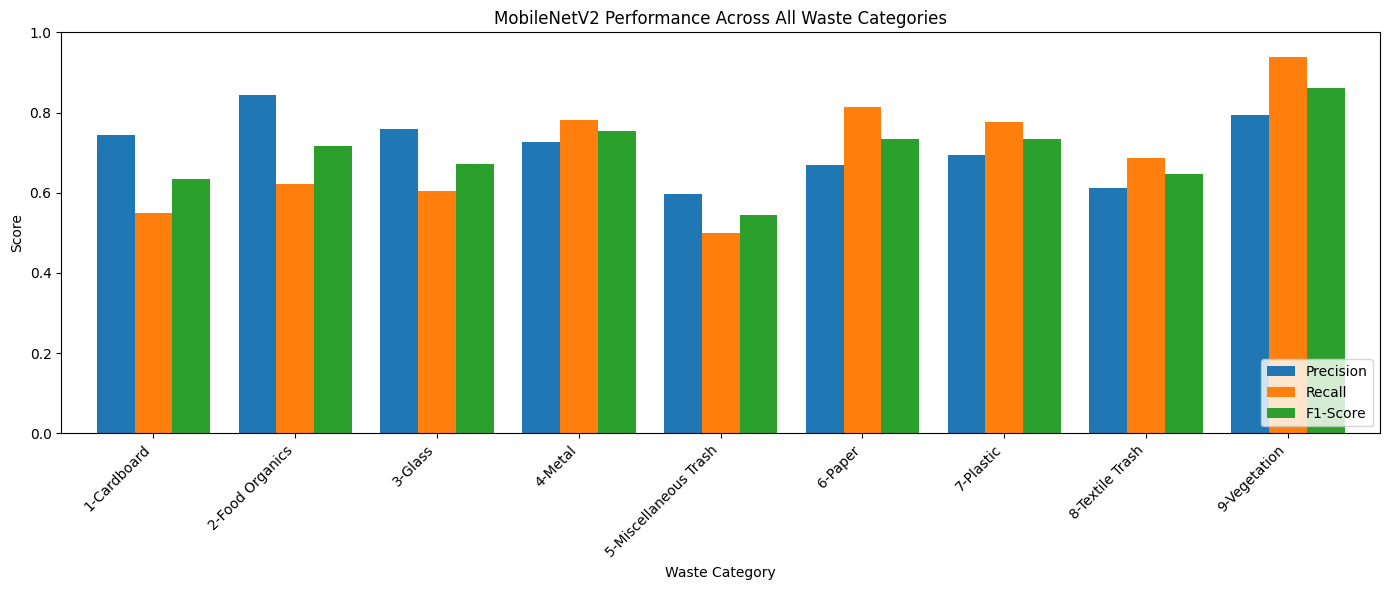

In [100]:
# Calculate precision, recall, and F1-score for all categories
from sklearn.metrics import precision_recall_fscore_support

precision, recall, f1_score, support = precision_recall_fscore_support(
    mobilenet_y_true,
    mobilenet_y_pred,
    labels=np.arange(len(label_encoder.classes_)),
    zero_division=0
)

# Create a DataFrame containing the results
class_performance_df = pd.DataFrame({
    "Category": label_encoder.classes_,
    "Precision": precision,
    "Recall": recall,
    "F1-Score": f1_score,
    "Support": support
})

# Display the performance table
display(class_performance_df.round(3))


# Visualize the performance of all nine categories
class_performance_df.set_index("Category")[
    ["Precision", "Recall", "F1-Score"]
].plot(
    kind="bar",
    figsize=(14, 6),
    ylim=(0, 1),
    width=0.8
)

plt.title("MobileNetV2 Performance Across All Waste Categories")
plt.xlabel("Waste Category")
plt.ylabel("Score")
plt.xticks(rotation=45, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [101]:
# Evaluate the selected MobileNetV2 model on unseen test images
mobilenet_test_loss, mobilenet_test_accuracy = best_mobilenet_model.evaluate(
    mobilenet_test_dataset
)

print(f"Test Accuracy: {mobilenet_test_accuracy * 100:.2f}%")
print(f"Test Loss: {mobilenet_test_loss:.4f}")

23/23 ━━━━━━━━━━━━━━━━━━━━ 10s 374ms/step - accuracy: 0.6999 - loss: 0.7795
Test Accuracy: 69.99%
Test Loss: 0.7795


In [102]:
# Evaluate the Custom CNN model on unseen test images
cnn_test_loss, cnn_test_accuracy = best_cnn_model.evaluate(
    X_test_normalized,
    y_test
)

print(f"Custom CNN Test Accuracy: {cnn_test_accuracy * 100:.2f}%")
print(f"Custom CNN Test Loss: {cnn_test_loss:.4f}")

23/23 ━━━━━━━━━━━━━━━━━━━━ 4s 162ms/step - accuracy: 0.5610 - loss: 1.1418
Custom CNN Test Accuracy: 56.10%
Custom CNN Test Loss: 1.1418


In [103]:
# Generate Custom CNN predictions on unseen test images
cnn_test_prob = best_cnn_model.predict(X_test_normalized)
cnn_test_pred = np.argmax(cnn_test_prob, axis=1)

# Display the test classification report
print("Custom CNN - Test Classification Report")

print(classification_report(
    y_test,
    cnn_test_pred,
    target_names=label_encoder.classes_,
    zero_division=0
))

23/23 ━━━━━━━━━━━━━━━━━━━━ 4s 169ms/step
Custom CNN - Test Classification Report
                       precision    recall  f1-score   support

          1-Cardboard       0.79      0.43      0.56        69
      2-Food Organics       0.72      0.68      0.70        62
              3-Glass       0.67      0.44      0.53        63
              4-Metal       0.54      0.50      0.52       118
5-Miscellaneous Trash       0.31      0.49      0.38        75
              6-Paper       0.66      0.49      0.56        75
            7-Plastic       0.50      0.73      0.59       138
      8-Textile Trash       0.57      0.17      0.26        48
         9-Vegetation       0.76      0.89      0.82        65

             accuracy                           0.56       713
            macro avg       0.61      0.54      0.55       713
         weighted avg       0.60      0.56      0.56       713



In [104]:
# Generate MobileNetV2 predictions on unseen test images
mobilenet_test_y_true = np.concatenate([
    labels.numpy()
    for images, labels in mobilenet_test_dataset
])

mobilenet_test_y_prob = best_mobilenet_model.predict(
    mobilenet_test_dataset
)

mobilenet_test_y_pred = np.argmax(
    mobilenet_test_y_prob,
    axis=1
)

# Display the test classification report
print("MobileNetV2 - Test Classification Report")

print(classification_report(
    mobilenet_test_y_true,
    mobilenet_test_y_pred,
    target_names=label_encoder.classes_,
    zero_division=0
))

23/23 ━━━━━━━━━━━━━━━━━━━━ 12s 459ms/step
MobileNetV2 - Test Classification Report
                       precision    recall  f1-score   support

          1-Cardboard       0.75      0.61      0.67        69
      2-Food Organics       0.88      0.68      0.76        62
              3-Glass       0.61      0.57      0.59        63
              4-Metal       0.67      0.75      0.71       118
5-Miscellaneous Trash       0.60      0.48      0.53        75
              6-Paper       0.66      0.79      0.72        75
            7-Plastic       0.63      0.70      0.67       138
      8-Textile Trash       0.84      0.77      0.80        48
         9-Vegetation       0.86      0.95      0.91        65

             accuracy                           0.70       713
            macro avg       0.72      0.70      0.71       713
         weighted avg       0.70      0.70      0.70       713



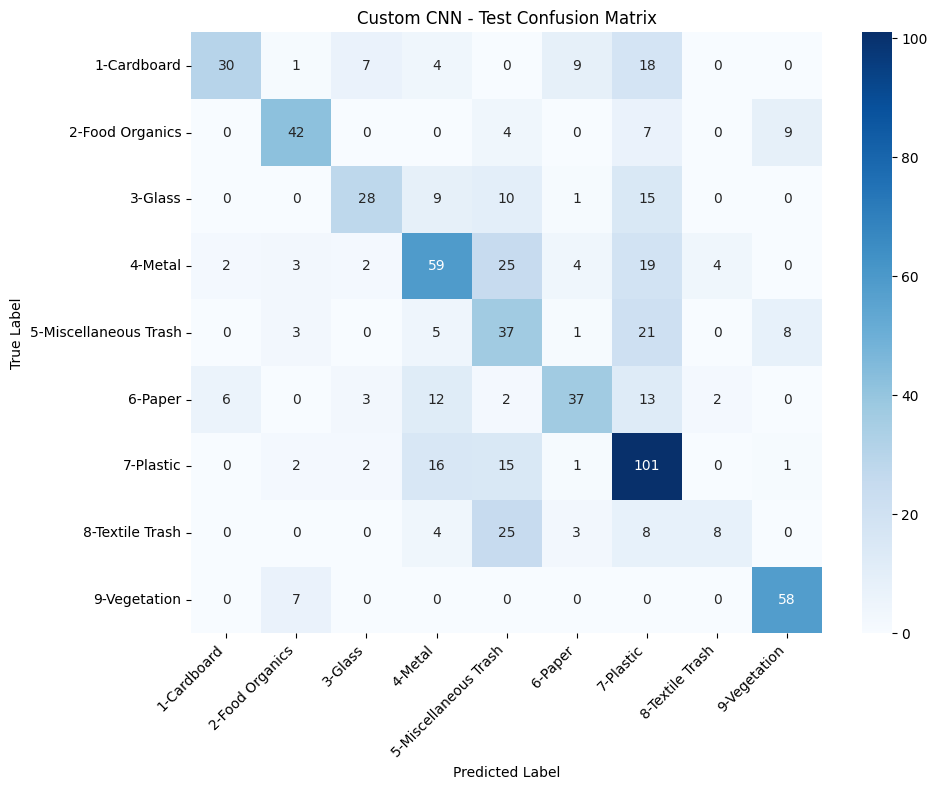

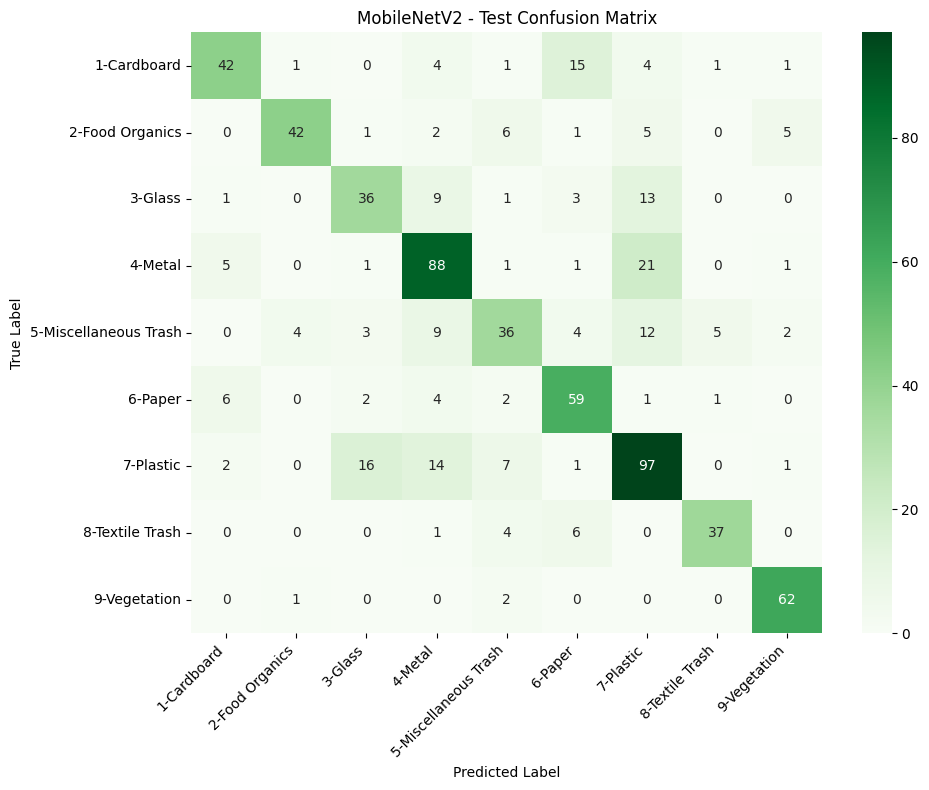

In [107]:
# Generate confusion matrices for both models
cnn_test_cm = confusion_matrix(y_test, cnn_test_pred)

mobilenet_test_cm = confusion_matrix(
    mobilenet_test_y_true,
    mobilenet_test_y_pred
)

# Plot Custom CNN confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(
    cnn_test_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.title("Custom CNN - Test Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Plot MobileNetV2 confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(
    mobilenet_test_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.title("MobileNetV2 - Test Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


## Final Model Evaluation

### 1. Model Comparison

Two deep learning models were developed and evaluated using the same training, validation, and independent test datasets:

- Custom CNN
- MobileNetV2 Transfer Learning

The following table summarizes their performance:

| Evaluation Metric | Custom CNN | MobileNetV2 |
|---|---:|---:|
| Validation Accuracy | 58.06% | 71.11% |
| Validation Loss | 1.1303 | 0.7891 |
| Validation Macro F1-Score | 0.55 | 0.70 |
| Validation Weighted F1-Score | 0.56 | 0.71 |
| Test Accuracy | 56.10% | 69.99% |
| Test Loss | 1.1418 | 0.7795 |
| Test Macro F1-Score | 0.55 | 0.71 |
| Test Weighted F1-Score | 0.56 | 0.70 |

MobileNetV2 achieved a 13.05 percentage-point improvement in validation accuracy and a 13.89 percentage-point improvement in independent test accuracy compared with the Custom CNN.

It also achieved higher macro F1-scores and lower loss values, demonstrating stronger overall classification performance.

### 2. Category-Level Performance

The classification reports showed different performance levels across the nine waste categories.

**Custom CNN:**
- Best-performing category: Vegetation (test F1-score: 0.82).
- Weakest-performing category: Textile Trash (test F1-score: 0.26).

**MobileNetV2:**
- Best-performing category: Vegetation (test F1-score: 0.91).
- Weakest-performing category: Miscellaneous Trash (test F1-score: 0.53).

MobileNetV2 achieved a higher test F1-score than the Custom CNN across all nine categories.

### 3. Error Analysis

The test confusion matrices were used to investigate classification errors and identify categories that the models struggled to distinguish.

For the Custom CNN, Textile Trash was frequently misclassified as Miscellaneous Trash (25 images). Metal was also confused with Miscellaneous Trash (25 images) and Plastic (19 images).

For MobileNetV2, the main classification errors involved visually similar waste categories. Metal was sometimes confused with Plastic (21 images), while Plastic was confused with Glass (16 images) and Metal (14 images).

Despite these errors, MobileNetV2 demonstrated better classification performance across all nine categories.

### 4. Dataset and Evaluation Limitations

- Total dataset: **4,752 images**.
- Training set: **3,326 images (70%)**.
- Validation set: **713 images (15%)**.
- Independent test set: **713 images (15%)**.

Both models were trained using the training set and evaluated using the validation set during model development. The independent test dataset was kept separate and used for the final evaluation.

The dataset contains different numbers of images across categories, which may have influenced classification performance, particularly for more challenging categories.

### 5. Conclusion

MobileNetV2 was selected as the final model because it achieved higher validation and independent test accuracy, lower loss values, and stronger macro F1-scores than the Custom CNN.

Its test accuracy of 69.99% compared with 56.10% for the Custom CNN demonstrates the advantage of transfer learning for this waste classification task.

The category-level analysis also showed that MobileNetV2 performed better across all nine categories, although Miscellaneous Trash remained challenging.

Future improvements could include collecting additional images for difficult categories, investigating class imbalance, experimenting with fine-tuning the pretrained layers, and exploring more advanced data augmentation techniques.

Overall, the project successfully developed and evaluated two deep learning approaches for classifying nine waste categories, with MobileNetV2 achieving the best overall performance.